# Computational Methods – überarbeitete Studienübungen

Python-Neufassungen früherer MATLAB-Übungen: Monte-Carlo-Verfahren, globales Sequenzalignment, Ziffernklassifikation und kombinatorische Optimierung. Zum Teil für Lehre während Masterarbeit verwendet und erstellt.

Jede Übung hat eine eigene Codezelle mit Definitionen, Beispiel und grundlegenden Assertions. 

## Umgebung
Python 3.10+; NumPy, pandas, Matplotlib, scikit-learn und Jupyter.

Installation bei Bedarf im Terminal:
```bash
python -m pip install numpy pandas matplotlib scikit-learn jupyter
```
Die Tests sind kleine Plausibilitäts- und Regressionstests, keine vollständige formale Verifikation.

In [1]:
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display as _display, HTML

def display(obj):
    """Standard-HTML-Ausgabe für portable Notebook-Tabellen."""
    _display(HTML(obj.to_html()) if isinstance(obj, pd.DataFrame) else obj)

print({"Python": platform.python_version(), "NumPy": np.__version__,
       "pandas": pd.__version__, "scikit-learn": sklearn.__version__})


def positive_int(value, name):
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value <= 0:
        raise ValueError(f"{name} muss eine positive ganze Zahl sein.")
    return int(value)

{'Python': '3.12.8', 'NumPy': '1.26.4', 'pandas': '2.2.3', 'scikit-learn': '1.6.1'}


## 1. π mit Hit-and-Miss-Monte-Carlo
Original: `Approximation_Pi.m`. Gleichverteilte Punkte im Quadrat [0,r]²; der Anteil innerhalb des Viertelkreises schätzt π/4. Rückgabe: Schätzung und Monte-Carlo-Standardfehler. Die Implementierung arbeitet blockweise, um den Speicherbedarf zu begrenzen. Ein Seed macht das Beispiel reproduzierbar, nicht die Schätzung exakt.

,estimate,standard_error,n,hits
0,3.04000,0.170833,100,76
1,3.08400,0.053150,1000,771
2,3.16000,0.016292,10000,7900
3,3.15008,0.005174,100000,78752


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 960 (\N{GREEK SMALL LETTER PI}) missing from font(s) FK Grotesk Neue.
  fig.canvas.print_figure(bytes_io, **kw)


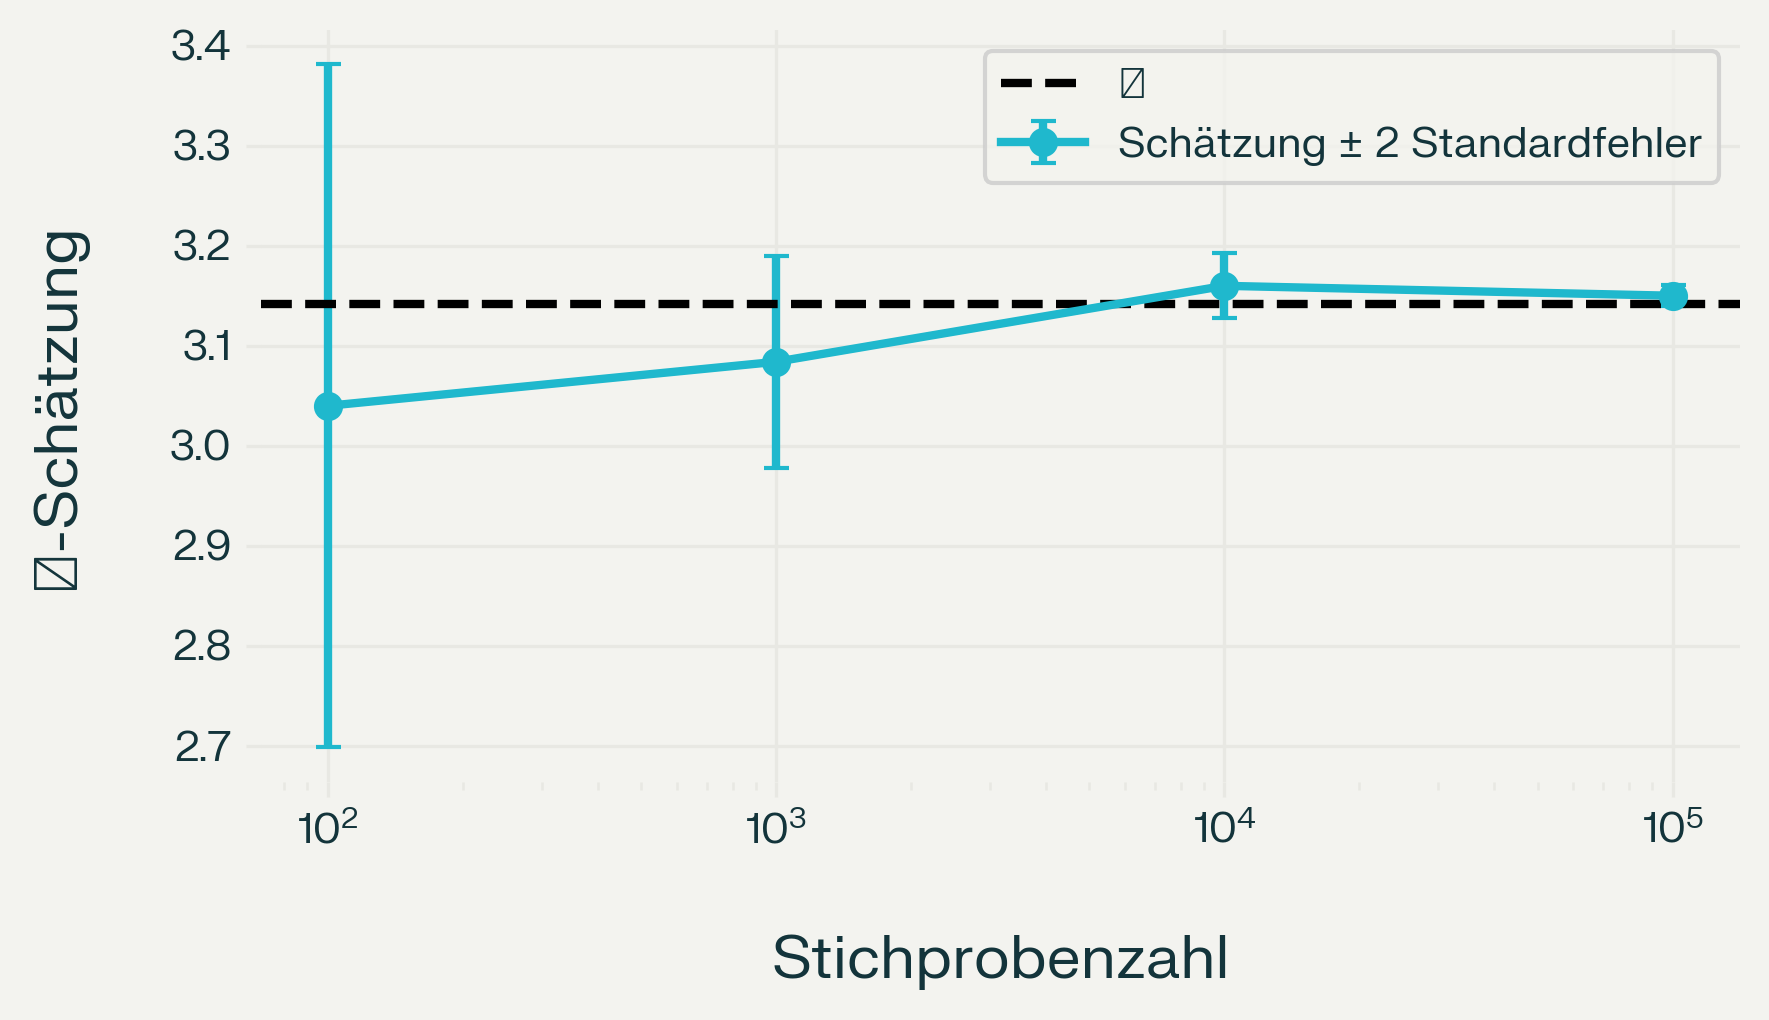

In [2]:
def approximate_pi(n=100_000, radius=1.0, seed=42, batch_size=100_000):
    """Schätze π durch den Flächenanteil eines Viertelkreises."""
    n = positive_int(n, "n")
    batch_size = positive_int(batch_size, "batch_size")
    if not np.isfinite(radius) or radius <= 0:
        raise ValueError("radius muss endlich und positiv sein.")
    rng = np.random.default_rng(seed)
    hits = 0
    for start in range(0, n, batch_size):
        points = rng.random((min(batch_size, n - start), 2))
        hits += np.count_nonzero(np.sum(points**2, axis=1) <= 1)
    fraction = hits / n
    return {"estimate": 4 * fraction,
            "standard_error": 4 * np.sqrt(fraction * (1 - fraction) / n),
            "n": n, "hits": int(hits)}


pi_result = approximate_pi()
assert pi_result == approximate_pi()
assert approximate_pi(radius=4) == pi_result
assert abs(pi_result["estimate"] - np.pi) < 0.05
sizes = [100, 1_000, 10_000, 100_000]
pi_convergence = pd.DataFrame([approximate_pi(n=n) for n in sizes])
display(pi_convergence)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(pi_convergence.n, pi_convergence.estimate,
            yerr=2*pi_convergence.standard_error, fmt="o-", capsize=3,
            label="Schätzung ± 2 Standardfehler")
ax.axhline(np.pi, color="black", ls="--", label="π")
ax.set(xscale="log", xlabel="Stichprobenzahl", ylabel="π-Schätzung")
ax.legend(); plt.show()

## 2. Einfache Monte-Carlo-Integration
Original: `Integralapprox.m`. Für X ~ Uniform(a,b) gilt Integral = (b−a) E[f(X)]. Anders als beim ursprünglichen Entwurf werden tatsächlich n Stichproben verwendet. Die Funktion f muss einzelne numerische Werte akzeptieren und einen endlichen Skalar liefern. Der Standardfehler beschreibt Stichprobenunsicherheit, keinen garantierten Fehlerbereich.

In [3]:
def integral_approx(n, f, a, b, seed=42):
    """Monte-Carlo-Integral und geschätzter Standardfehler."""
    n = positive_int(n, "n")
    a, b = float(a), float(b)
    if not np.isfinite([a, b]).all() or b <= a:
        raise ValueError("Erforderlich: endliche Grenzen a < b.")
    rng = np.random.default_rng(seed)
    values = np.array([float(f(x)) for x in rng.uniform(a, b, n)])
    if not np.isfinite(values).all():
        raise ValueError("f erzeugt nicht-endliche Werte.")
    estimate = (b-a) * values.mean()
    se = (b-a) * values.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
    return float(estimate), float(se)


assert integral_approx(20, lambda x: 1, 2, 5)[0] == 3
integral_estimate, integral_se = integral_approx(50_000, lambda x: x**2, 0, 1)
assert abs(integral_estimate - 1/3) < 0.02
print(f"Integral von x² auf [0,1]: {integral_estimate:.6f}; "
      f"Standardfehler: {integral_se:.6f}; exakt: {1/3:.6f}")

Integral von x² auf [0,1]: 0.334192; Standardfehler: 0.001332; exakt: 0.333333


## 3. Monte-Carlo-Integration mit Konvergenzverlauf
Original: `Integralapproximation.m`. Ausgabe nach jeweils `block_size` Punkten; ein letzter unvollständiger Block wird korrekt berücksichtigt. Jeder Zwischenwert ist bereits mit der Intervalllänge skaliert. Es werden genau n Punkte verwendet, nicht s+1 je Block.

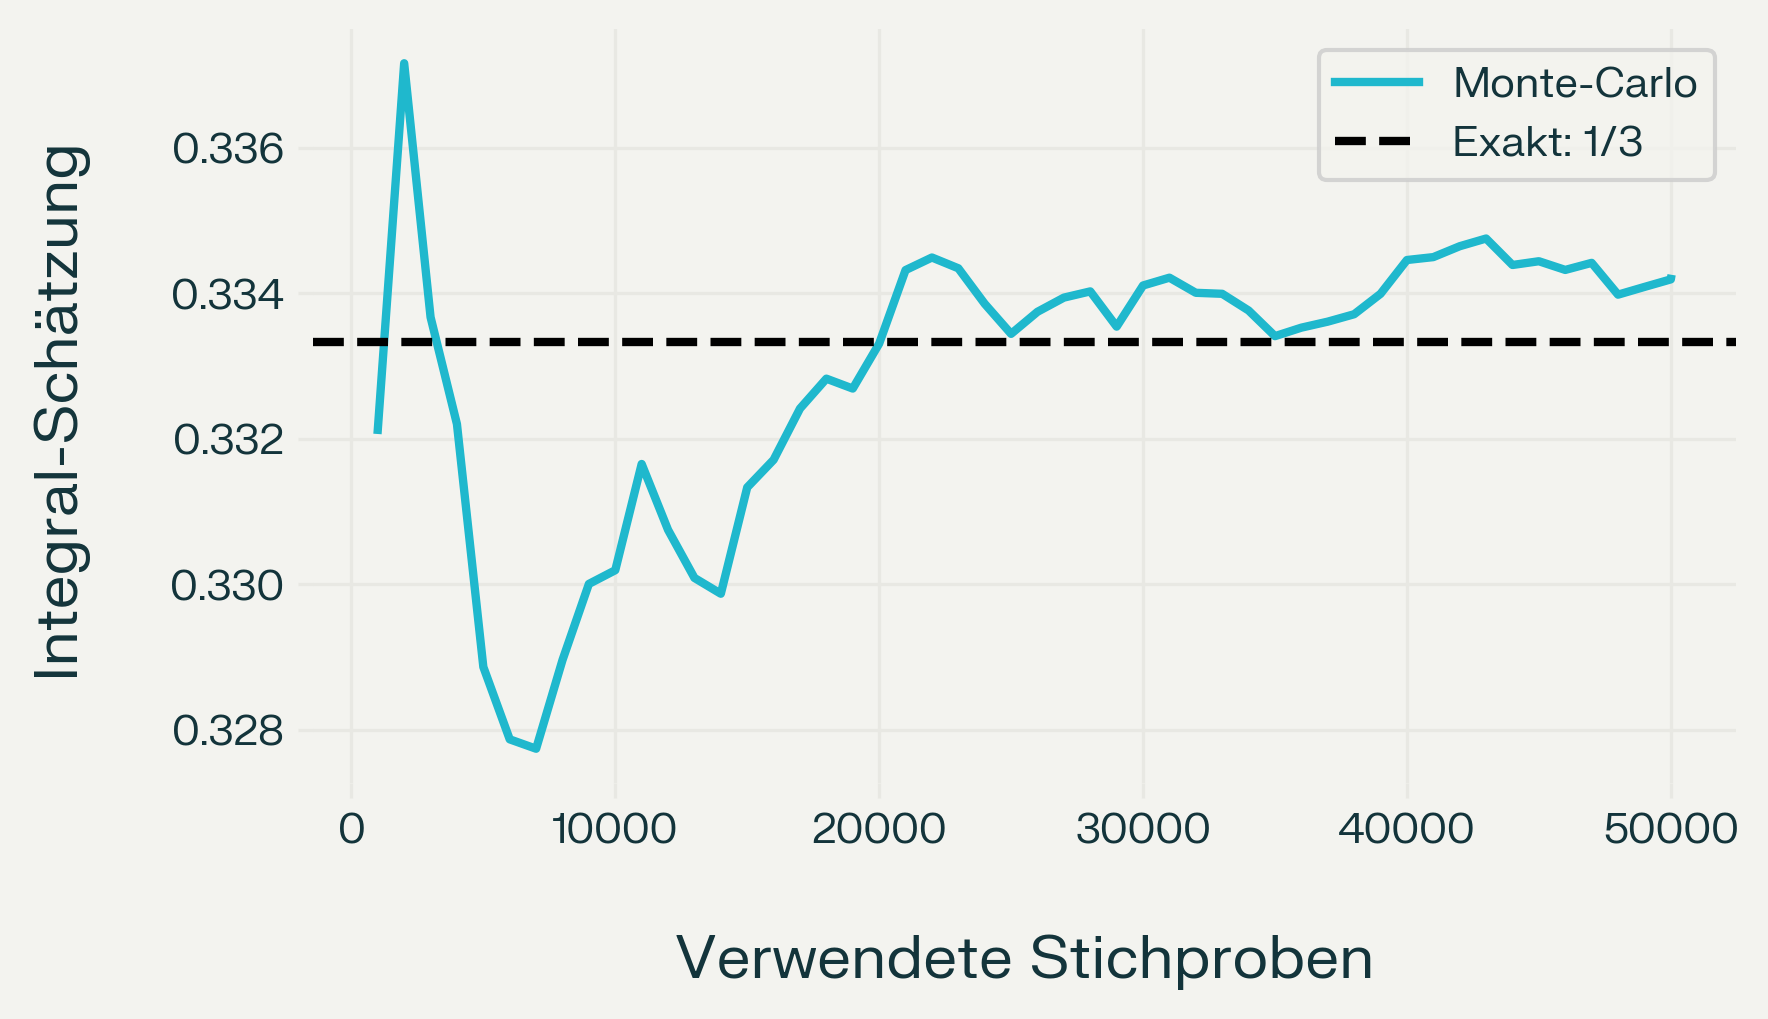

In [4]:
def integral_with_history(n, f, a, b, block_size=1_000, seed=42):
    """Rückgabe: Integral-Schätzung und Tabelle kumulativer Schätzungen."""
    n = positive_int(n, "n")
    block_size = positive_int(block_size, "block_size")
    a, b = float(a), float(b)
    if not np.isfinite([a, b]).all() or b <= a:
        raise ValueError("Erforderlich: endliche Grenzen a < b.")
    rng = np.random.default_rng(seed)
    total = 0.0
    history = []
    for start in range(0, n, block_size):
        count = min(block_size, n-start)
        values = np.array([float(f(x)) for x in rng.uniform(a, b, count)])
        if not np.isfinite(values).all():
            raise ValueError("f erzeugt nicht-endliche Werte.")
        total += values.sum()
        used = start + count
        history.append({"n": used, "estimate": (b-a)*total/used})
    table = pd.DataFrame(history)
    return float(table.iloc[-1]["estimate"]), table


constant, constant_history = integral_with_history(103, lambda x: 1, 2, 5, 20)
assert constant == 3
assert constant_history.iloc[-1]["n"] == 103
assert np.allclose(constant_history.estimate, 3)
value, integral_history = integral_with_history(50_003, lambda x: x**2, 0, 1)
assert np.isclose(value, integral_approx(50_003, lambda x: x**2, 0, 1)[0])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(integral_history.n, integral_history.estimate, label="Monte-Carlo")
ax.axhline(1/3, color="black", ls="--", label="Exakt: 1/3")
ax.set(xlabel="Verwendete Stichproben", ylabel="Integral-Schätzung")
ax.legend(); plt.show()

## 4. Needleman–Wunsch: globales Sequenzalignment
Original: `nw.m`. Vollständige dynamische Programmierung mit Traceback und linearer Gap-Strafe.

- `match` und `mismatch` sind Scores; `gap` ist eine positive Strafhöhe und wird subtrahiert.
- Rückgabe: optimaler Score, zwei alignierte Sequenzen und Score-Matrix.
- Bei gleichwertigen Wegen: Diagonale vor vertikalem vor horizontalem Schritt. Es wird genau ein optimales Alignment ausgegeben.
- Keine affinen Gap-Kosten oder biologischen Substitutionsmatrizen; Laufzeit und Speicher O(mn).
- Die Eingabe darf keine `-` enthalten, da dies das Ausgabesymbol für Lücken ist.

In [5]:
def needleman_wunsch(s, t, match=1.0, mismatch=-1.0, gap=1.0):
    """Globales Alignment zweier Zeichenketten mit linearen Gap-Kosten."""
    if not isinstance(s, str) or not isinstance(t, str):
        raise TypeError("s und t müssen Zeichenketten sein.")
    if "-" in s or "-" in t:
        raise ValueError("Eingaben dürfen keine Gap-Zeichen '-' enthalten.")
    if not np.isfinite([match, mismatch, gap]).all() or gap < 0:
        raise ValueError("Scores müssen endlich und gap nichtnegativ sein.")
    m, n = len(s), len(t)
    scores = np.zeros((m+1, n+1), dtype=float)
    trace = np.zeros((m+1, n+1), dtype=np.uint8)
    scores[:, 0] = -gap * np.arange(m+1)
    scores[0, :] = -gap * np.arange(n+1)
    trace[1:, 0], trace[0, 1:] = 1, 2
    for i in range(1, m+1):
        for j in range(1, n+1):
            candidates = [scores[i-1, j-1] + (match if s[i-1] == t[j-1] else mismatch),
                          scores[i-1, j] - gap, scores[i, j-1] - gap]
            direction = int(np.argmax(candidates))
            scores[i, j] = candidates[direction]
            trace[i, j] = direction
    aligned_s, aligned_t = [], []
    i, j = m, n
    while i or j:
        direction = trace[i, j]
        if direction == 0:
            aligned_s.append(s[i-1]); aligned_t.append(t[j-1])
            i -= 1; j -= 1
        elif direction == 1:
            aligned_s.append(s[i-1]); aligned_t.append("-")
            i -= 1
        else:
            aligned_s.append("-"); aligned_t.append(t[j-1])
            j -= 1
    return {"score": float(scores[m, n]),
            "aligned_s": "".join(reversed(aligned_s)),
            "aligned_t": "".join(reversed(aligned_t)),
            "matrix": scores}


def alignment_score(a, b, match=1.0, mismatch=-1.0, gap=1.0):
    """Unabhängige Nachberechnung eines bereits erzeugten Alignments."""
    if len(a) != len(b) or any(x == y == "-" for x, y in zip(a, b)):
        raise ValueError("Ungültiges Alignment.")
    return sum(-gap if "-" in (x, y) else match if x == y else mismatch
               for x, y in zip(a, b))


assert needleman_wunsch("", "")["score"] == 0
assert needleman_wunsch("AC", "")["score"] == -2
assert needleman_wunsch("", "AC")["score"] == -2
assert needleman_wunsch("ACGT", "ACGT")["score"] == 4
assert needleman_wunsch("A", "T")["score"] == -1
assert needleman_wunsch("AG", "A")["score"] == 0
alignment = needleman_wunsch("GATTACA", "GCATGCU")
assert alignment["score"] == 0
assert alignment["aligned_s"].replace("-", "") == "GATTACA"
assert alignment["aligned_t"].replace("-", "") == "GCATGCU"
assert alignment_score(alignment["aligned_s"], alignment["aligned_t"]) == alignment["score"]
print(alignment["aligned_s"])
print(alignment["aligned_t"])
print("Score:", alignment["score"])
display(pd.DataFrame(alignment["matrix"],
                     index=["∅"] + list("GATTACA"), columns=["∅"] + list("GCATGCU")))

G-ATTACA
GCA-TGCU
Score: 0.0


,∅,G,C,A,T,G,C,U
∅,-0.0,-1.0,-2.0,-3.0,-4.0,-5.0,-6.0,-7.0
G,-1.0,1.0,0.0,-1.0,-2.0,-3.0,-4.0,-5.0
A,-2.0,0.0,0.0,1.0,0.0,-1.0,-2.0,-3.0
T,-3.0,-1.0,-1.0,0.0,2.0,1.0,0.0,-1.0
T,-4.0,-2.0,-2.0,-1.0,1.0,1.0,0.0,-1.0
A,-5.0,-3.0,-3.0,-1.0,0.0,0.0,0.0,-1.0
C,-6.0,-4.0,-2.0,-2.0,-1.0,-1.0,1.0,0.0
A,-7.0,-5.0,-3.0,-1.0,-2.0,-2.0,0.0,0.0


## 5. Ziffernklassifikation mit einem neuronalen Netz
Original: `matlab_nn.m`. Python-Neufassung mit `MLPClassifier` und dem lokal mitgelieferten Digits-Datensatz (8×8-Pixel-Bilder). Das ist **kein Residual Network** und kein direkt reproduzierter Benchmark des alten MATLAB-Modells.

Stratifizierter Train/Test-Split; Skalierung wird nur auf Trainingsdaten angepasst. Ein einfacher Klassenhäufigkeits-Baselineklassifikator dient zum Vergleich. Das Testset wird einmal ausgewertet, nicht zur Parameterwahl verwendet. Gezeigt werden Genauigkeit und Konfusionsmatrix. Das Modell ist ein didaktisches Beispiel, keine klinische Anwendung.

{'accuracy': 0.9822222222222222, 'baseline_accuracy': 0.10222222222222223, 'n_train': 1347, 'n_test': 450}


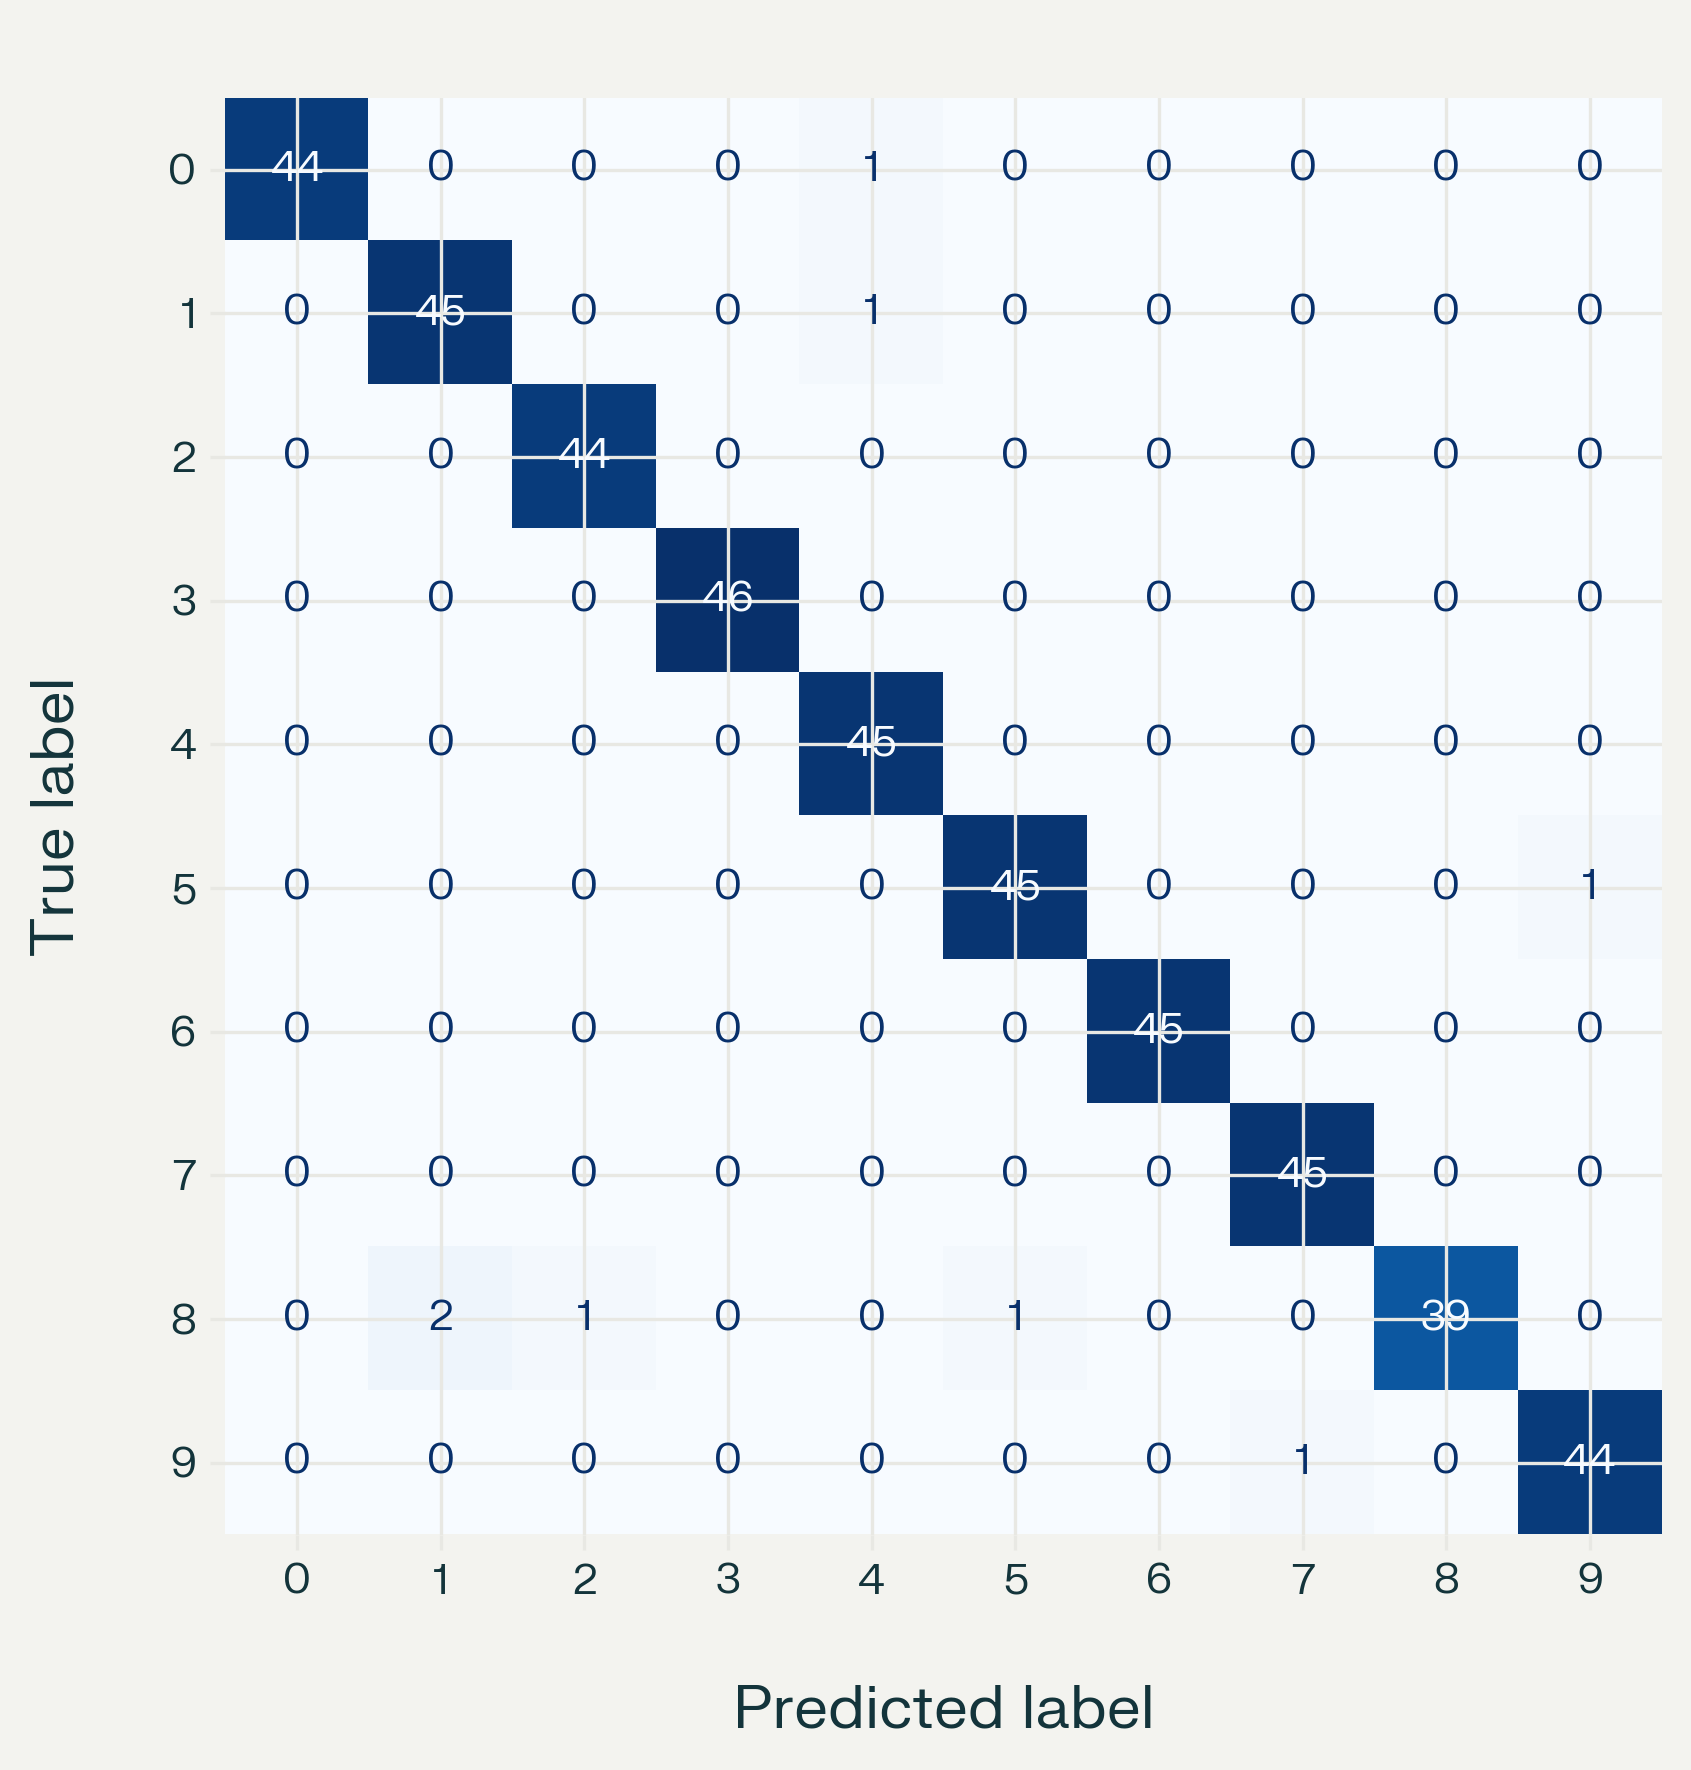

In [6]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay


def train_digit_classifier(seed=42):
    """Trainiere ein kleines MLP; liefere Modell und Testauswertung zurück."""
    digits = load_digits()
    X_train, X_test, y_train, y_test = train_test_split(
        digits.data, digits.target, test_size=0.25,
        random_state=seed, stratify=digits.target)
    model = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(32, 16), solver="lbfgs",
                      alpha=0.1, max_iter=500, max_fun=30000, random_state=seed))
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
    return {"model": model, "X_test": X_test, "y_test": y_test,
            "prediction": prediction,
            "accuracy": accuracy_score(y_test, prediction),
            "baseline_accuracy": accuracy_score(y_test, baseline.predict(X_test)),
            "n_train": len(y_train), "n_test": len(y_test)}


digits_result = train_digit_classifier()
assert digits_result["prediction"].shape == digits_result["y_test"].shape
assert set(digits_result["prediction"]).issubset(set(range(10)))
assert 0 <= digits_result["accuracy"] <= 1
print({key: digits_result[key] for key in
       ["accuracy", "baseline_accuracy", "n_train", "n_test"]})
ConfusionMatrixDisplay.from_predictions(digits_result["y_test"], digits_result["prediction"],
                                        cmap="Blues", colorbar=False)
plt.title("Digits-Testset: Konfusionsmatrix")
plt.show()

## 6. Zulässigen Nachbarzustand ziehen
Original: `drawone.m`. Zufälliges Flippen genau eines Bits. Wenn die Kapazität überschritten würde, bleibt der bisherige Zustand erhalten. Eingaben werden als eindimensionale Arrays behandelt. Im nächsten Abschnitt wird diese Funktion für das Rucksackproblem genutzt.

In [7]:
def draw_one(x, weights, capacity, rng):
    """Ein zufälliger Bit-Flip, sofern die Kapazitätsbedingung erfüllt ist."""
    state = np.asarray(x)
    weights = np.asarray(weights, dtype=float)
    if state.ndim != 1 or weights.ndim != 1 or len(state) != len(weights) or len(state) == 0:
        raise ValueError("x und weights müssen gleich lange, nichtleere 1D-Arrays sein.")
    if not np.isin(state, [0, 1]).all():
        raise ValueError("x muss binär sein.")
    if not np.isfinite(weights).all() or (weights <= 0).any():
        raise ValueError("Gewichte müssen endlich und positiv sein.")
    if not np.isfinite(capacity) or capacity < 0 or state @ weights > capacity:
        raise ValueError("Kapazität ungültig oder Ausgangszustand nicht zulässig.")
    candidate = state.astype(int, copy=True)
    index = int(rng.integers(len(state)))
    candidate[index] = 1 - candidate[index]
    return candidate if candidate @ weights <= capacity else state.astype(int, copy=True)


initial = np.array([0, 0, 0])
neighbor = draw_one(initial, [2, 3, 4], 5, np.random.default_rng(42))
assert np.sum(initial != neighbor) <= 1
assert neighbor @ np.array([2, 3, 4]) <= 5
assert np.array_equal(initial, [0, 0, 0])
assert np.array_equal(draw_one([0], [10], 1, np.random.default_rng(0)), [0])
print("Start:", initial, "Nachbar:", neighbor)

Start: [0 0 0] Nachbar: [1 0 0]


## 7. Rucksackproblem mit Simulated Annealing
Original: `rucksack.m`. Ziel: Gesamtwert maximieren bei begrenztem Gewicht. Die unfertige temperaturabhängige Idee wird hier zu einer vollständigen Heuristik ergänzt: Verbesserungen werden angenommen; Verschlechterungen mit exp(ΔWert/T). Die beste gefundene Lösung bleibt gespeichert.

Die Heuristik garantiert **kein globales Optimum**. Für kleine Beispiele wird daher zusätzlich durch vollständige Enumeration eine exakte Lösung bestimmt. Dies ist eine Referenz für das Beispiel, kein skalierbarer Solver.

,method,value,weight
0,Simulated Annealing,12.0,8.0
1,Exakte Enumeration,12.0,8.0


Ausgewählte Objekte (0-basierte Indizes): [1 3]


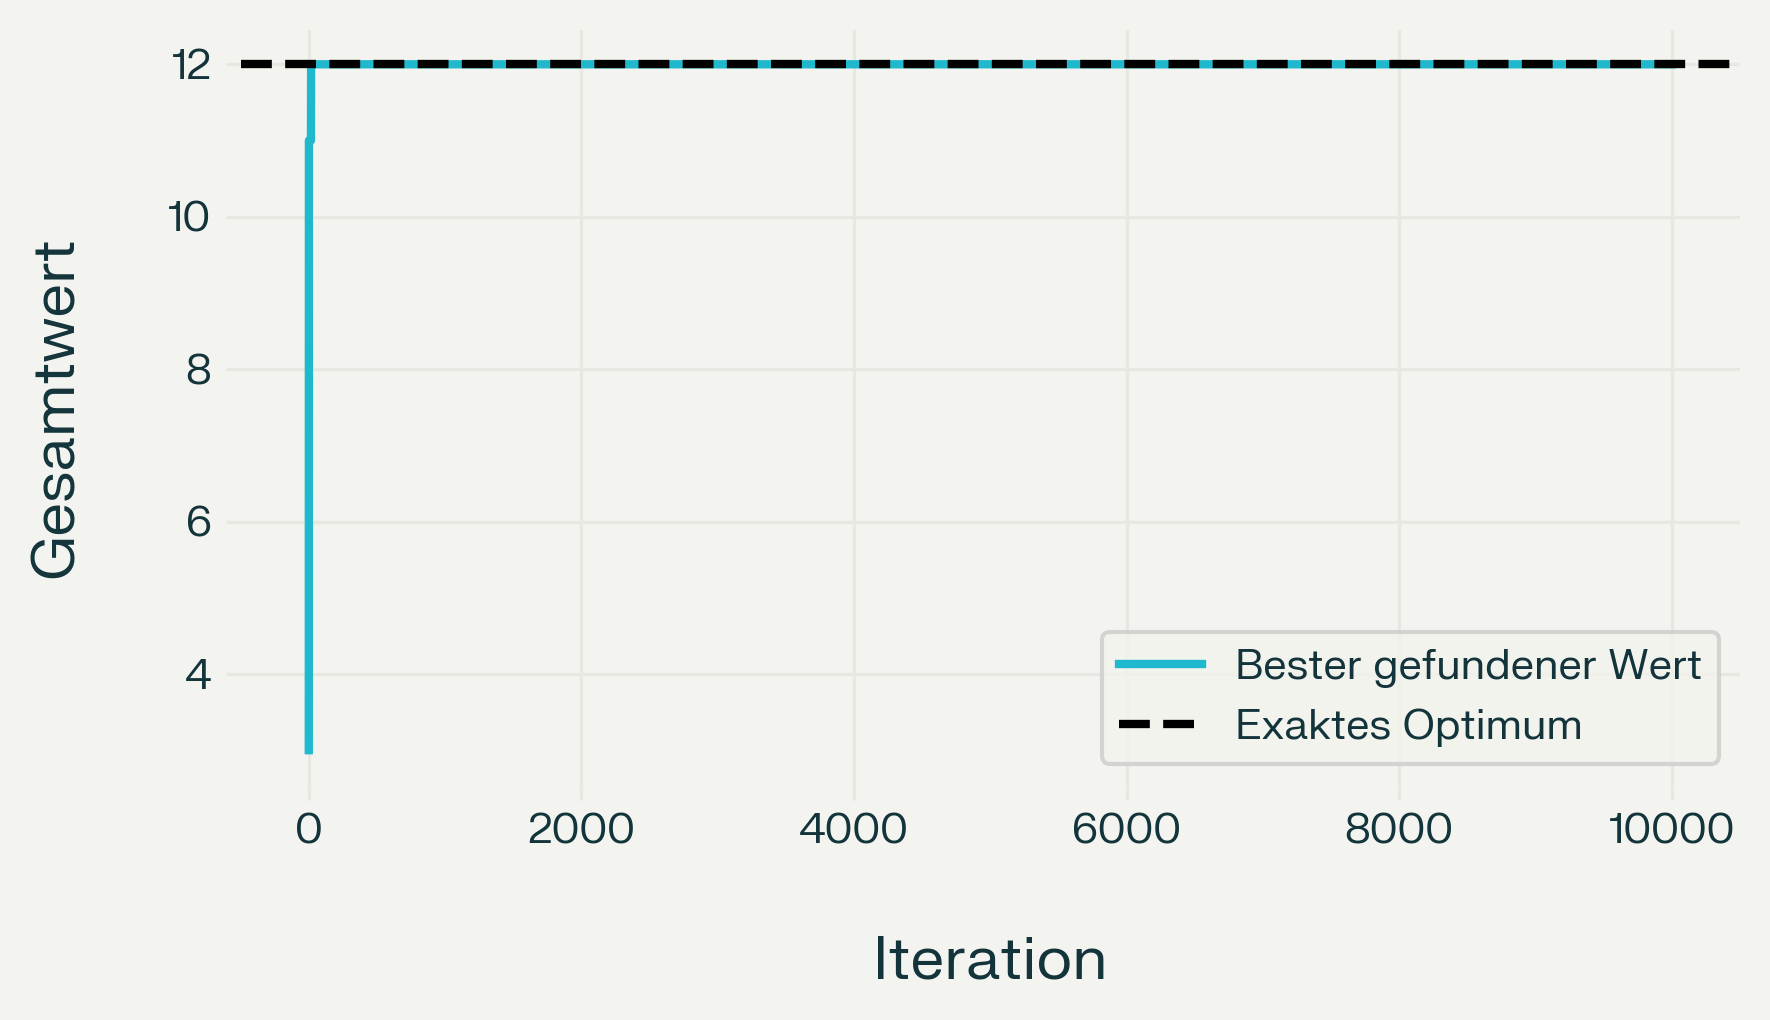

In [8]:
def validate_knapsack(weights, values, capacity):
    w, v = np.asarray(weights, dtype=float), np.asarray(values, dtype=float)
    if w.ndim != 1 or v.ndim != 1 or len(w) == 0 or w.shape != v.shape:
        raise ValueError("weights und values müssen gleich lange, nichtleere 1D-Arrays sein.")
    if not np.isfinite(w).all() or not np.isfinite(v).all() or (w <= 0).any() or (v < 0).any():
        raise ValueError("Endliche positive Gewichte und nichtnegative Werte erforderlich.")
    if not np.isfinite(capacity) or capacity < 0:
        raise ValueError("capacity muss endlich und nichtnegativ sein.")
    return w, v


def knapsack_annealing(weights, values, capacity, steps=10_000,
                        initial_temperature=10.0, final_temperature=0.01, seed=42):
    """Heuristische 0/1-Rucksackoptimierung; keine Optimalitätsgarantie."""
    w, v = validate_knapsack(weights, values, capacity)
    steps = positive_int(steps, "steps")
    if not np.isfinite([initial_temperature, final_temperature]).all() or not (
            initial_temperature >= final_temperature > 0):
        raise ValueError("Erforderlich: initial_temperature >= final_temperature > 0.")
    rng = np.random.default_rng(seed)
    current = np.zeros(len(w), dtype=int)
    current_value = 0.0
    best, best_value = current.copy(), current_value
    history = []
    for step, temperature in enumerate(np.geomspace(initial_temperature, final_temperature, steps), 1):
        candidate = draw_one(current, w, capacity, rng)
        candidate_value = float(candidate @ v)
        delta = candidate_value - current_value
        if delta >= 0 or rng.random() < np.exp(delta / temperature):
            current, current_value = candidate, candidate_value
        if current_value > best_value:
            best, best_value = current.copy(), current_value
        history.append({"step": step, "temperature": temperature,
                        "current_value": current_value, "best_value": best_value})
    return {"selection": best, "value": best_value, "weight": float(best @ w),
            "history": pd.DataFrame(history)}


def knapsack_exact_small(weights, values, capacity):
    """Vollständige Enumeration als kleine Testreferenz (maximal 20 Objekte)."""
    from itertools import product
    w, v = validate_knapsack(weights, values, capacity)
    if len(w) > 20:
        raise ValueError("Enumeration auf maximal 20 Objekte begrenzt.")
    best, best_value = np.zeros(len(w), dtype=int), 0.0
    for bits in product([0, 1], repeat=len(w)):
        x = np.asarray(bits)
        value = float(x @ v)
        if x @ w <= capacity and value > best_value:
            best, best_value = x, value
    return {"selection": best, "value": best_value, "weight": float(best @ w)}


weights, values, capacity = [2, 3, 4, 5], [3, 4, 5, 8], 8
annealed = knapsack_annealing(weights, values, capacity)
exact = knapsack_exact_small(weights, values, capacity)
assert exact["value"] == 12
assert annealed["weight"] <= capacity
assert annealed["value"] <= exact["value"]
assert np.isin(annealed["selection"], [0, 1]).all()
assert np.all(np.diff(annealed["history"].best_value) >= 0)
assert knapsack_annealing([2], [5], 0, steps=10)["value"] == 0
assert np.array_equal(annealed["selection"],
                      knapsack_annealing(weights, values, capacity)["selection"])
display(pd.DataFrame([
    {"method": "Simulated Annealing", "value": annealed["value"], "weight": annealed["weight"]},
    {"method": "Exakte Enumeration", "value": exact["value"], "weight": exact["weight"]}]))
print("Ausgewählte Objekte (0-basierte Indizes):", np.flatnonzero(annealed["selection"]))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(annealed["history"].step, annealed["history"].best_value, label="Bester gefundener Wert")
ax.axhline(exact["value"], ls="--", color="black", label="Exaktes Optimum")
ax.set(xlabel="Iteration", ylabel="Gesamtwert")
ax.legend(); plt.show()